# ***T20-CRICKET TEAM PERFORMANCE ANALYSIS PROJECT***

---



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

***Data Loading***

In [2]:
all_datasets = []
all_datasets.append(pd.read_csv("match_data_fixed.csv"))

df = pd.concat(all_datasets, ignore_index = True)

format_overs = 20
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Match_No            110 non-null    int64  
 1   Player_Name         110 non-null    object 
 2   Role                110 non-null    object 
 3   Batting_Position    110 non-null    int64  
 4   Batting_Start_Over  91 non-null     float64
 5   Out_Over            91 non-null     object 
 6   Balls_Played        91 non-null     float64
 7   Runs_Scored         91 non-null     float64
 8   Overs_Bowled        52 non-null     float64
 9   Runs_Given          52 non-null     float64
 10  Wickets_Taken       52 non-null     float64
dtypes: float64(6), int64(2), object(3)
memory usage: 9.6+ KB
None


***Data Validation***

In [3]:
def data_validation(df):
  out_over = pd.to_numeric(df["Out_Over"], errors="coerce")

  # T20 only, Out_Over can't be more than 20
  too_many_overs = out_over > 20
  if too_many_overs.any():
    print(df[too_many_overs])
    raise ValueError("Current Version only supports T20 data (Out_Over cannot exceed 20)")

  # max 11 players in a match
  players_per_match = df.groupby("Match_No")["Player_Name"].nunique()
  if (players_per_match > 11).any():
    print(players_per_match[players_per_match > 11])
    raise ValueError("A single match cannot have more than 11 players")

  # max 22 unique players in the whole dataset (2 matches at a time)
  if df["Player_Name"].nunique() > 22:
    raise ValueError("Dataset contains too many unique players. Please limit uploads to 2 matches at a time.")

  # NEW: a team can take at most 10 wickets in a single match
  wickets = pd.to_numeric(df["Wickets_Taken"], errors="coerce")
  wickets_per_match = wickets.groupby(df["Match_No"]).sum()
  if (wickets_per_match > 10).any():
    print(wickets_per_match[wickets_per_match > 10])
    raise ValueError("Total wickets taken in a single match cannot be more than 10")

  no_match = df["Match_No"].isnull()
  if no_match.any():
    print(df[no_match])
    raise ValueError("Some players don't have Match Number information, can't proceed")

  no_position = df["Batting_Position"].isnull()
  if no_position.any():
    print(df[no_position])
    raise ValueError("Some players don't have Batting Position information, can't proceed")

  start      = df["Batting_Start_Over"]
  balls      = df["Balls_Played"]
  runs       = df["Runs_Scored"]
  overs      = df["Overs_Bowled"]
  runs_given = df["Runs_Given"]
  wkts       = df["Wickets_Taken"]

  # a player without name can't have any other info
  other_cols = [df["Role"], df["Batting_Position"], start, df["Out_Over"], balls, runs, overs, runs_given, wkts]
  invalid_player = df["Player_Name"].isnull() & np.logical_or.reduce([c.notnull() for c in other_cols])
  if invalid_player.any():
    print(df[invalid_player])
    raise ValueError("Some players don't have their name, can't proceed")

  # Batting columns
  # no batting start but other batting stats are present
  bat_no_start_with_stats = start.isnull() & (df["Out_Over"].notnull() | balls.notnull() | runs.notnull())
  # UPDATED: Out_Over can be blank / "not-out" for a not-out batter, so it is not checked here anymore
  # batting start present but balls or runs missing
  bat_start_missing_stats = start.notnull() & (balls.isnull() | runs.isnull())
  # NEW: batter can't start after he is out
  bat_start_after_out     = start.notnull() & out_over.notnull() & (start > out_over)

  if bat_no_start_with_stats.any() or bat_start_missing_stats.any() or bat_start_after_out.any():
    print(df[bat_no_start_with_stats | bat_start_missing_stats | bat_start_after_out])
    raise ValueError("Invalid data found in batting columns, can't procced")

  # Bowling columns
  did_not_bowl = overs.isnull() | (overs == 0)
  # UPDATED: brackets fixed, earlier the "== 0" check was getting applied on the wrong part
  bowl_stats_without_overs = did_not_bowl & (runs_given.notnull() | wkts.notnull())
  # NEW: overs present but runs given or wickets missing
  bowl_overs_missing_stats = overs.notnull() & (overs > 0) & (runs_given.isnull() | wkts.isnull())

  if bowl_stats_without_overs.any() or bowl_overs_missing_stats.any():
    print(df[bowl_stats_without_overs | bowl_overs_missing_stats])
    raise ValueError("Invalid data found in bowling columns, can't procced")

  print("Dataset passed validation process, we can proceed further")

In [4]:
try:
  data_validation(df)
except Exception as err :
  print(f"Oops! We got some error as {err}")

Dataset passed validation process, we can proceed further


***Data Cleaning***

In [5]:
df2 = df.copy()

NEW - Standardizing Role and Out_Over columns

---


In [6]:
# Role : remove extra spaces and make lowercase, so "Batsman", " BATSMAN" and "batsman" are the same
role = df2["Role"].str.strip().str.lower()

# blank roles are filled with the most common role
role = role.fillna(role.mode()[0])

# wicketkeeper is treated as batsman
role = role.replace("wicketkeeper", "batsman")
df2["Role"] = role

# Out_Over can have text like "not-out", converting to numeric makes it NaN (filled with 0 in the next step)
df2["Out_Over"] = pd.to_numeric(df2["Out_Over"], errors="coerce")

Handling null values

---



In [7]:
try :
  fill_zero = ["Batting_Start_Over", "Out_Over", "Balls_Played", "Runs_Scored", "Overs_Bowled"]
  df2[fill_zero] = df2[fill_zero].fillna(0)
  df2[["Runs_Given", "Wickets_Taken"]] = df2[["Runs_Given", "Wickets_Taken"]].fillna(0)
  df2.info()
except Exception as err :
  print(f"Oops! we got an as exception as {err}")
  print("\n")
  print("Please use Valid Datatypes")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Match_No            110 non-null    int64  
 1   Player_Name         110 non-null    object 
 2   Role                110 non-null    object 
 3   Batting_Position    110 non-null    int64  
 4   Batting_Start_Over  110 non-null    float64
 5   Out_Over            110 non-null    float64
 6   Balls_Played        110 non-null    float64
 7   Runs_Scored         110 non-null    float64
 8   Overs_Bowled        110 non-null    float64
 9   Runs_Given          110 non-null    float64
 10  Wickets_Taken       110 non-null    float64
dtypes: float64(7), int64(2), object(2)
memory usage: 9.6+ KB


***Feature Engineering***

Creating boolean Batted and Was_Out columns for info of batted / out / not-out

---


In [8]:
# Batted : player came to bat
df2["Batted"] = df2["Batting_Start_Over"] > 0

# UPDATED: Was_Out is True only if the player has an Out_Over (not-out / did not bat gives False)
df2["Was_Out"] = df2["Out_Over"] > 0

Strike rate Column

---



In [9]:
# UPDATED: no division by zero, strike rate is 0 if the player has played 0 balls
df2["Strike_Rate"] = np.where(df2["Balls_Played"] > 0, df2["Runs_Scored"] / df2["Balls_Played"].where(df2["Balls_Played"] > 0, 1) * 100, 0.0)
df2["Strike_Rate"] = df2["Strike_Rate"].round(2)

NEW - Overs and Balls conversion

---


In [10]:
# Overs are written as O.B (3.4 = 3 overs 4 balls), so they must be added as balls, never as decimals
def balls_to_overs(balls):
  return np.round(balls // 6 + (balls % 6) / 10, 1)

Economy Rate Column

---



In [11]:
def economy_calc(df2):
  # UPDATED: overs (O.B format) are first converted into total balls
  full_overs = df2["Overs_Bowled"].astype(int)
  extra_balls = ((df2["Overs_Bowled"] - full_overs) * 10).round().astype(int)
  df2["Balls_Bowled"] = full_overs * 6 + extra_balls

  real_over = df2["Balls_Bowled"] / 6
  df2["Economy_Rate"] = np.where(real_over > 0, df2["Runs_Given"] / real_over.where(real_over > 0, 1), 0.0)
  df2["Economy_Rate"] = df2["Economy_Rate"].round(2)

  return df2

df2 = economy_calc(df2)

NEW - Batting Order group column

---


In [12]:
# batting position 1-3 is top, 4-7 is middle and 8-11 is lower order (used for the batting order analysis)
df2["Batting_Order"] = pd.cut(df2["Batting_Position"], bins = [0,3,7,11], labels=["top","middle","lower"]).astype(str)

In [13]:
df2.head()

,Match_No,Player_Name,Role,Batting_Position,Batting_Start_Over,Out_Over,Balls_Played,Runs_Scored,Overs_Bowled,Runs_Given,Wickets_Taken,Batted,Was_Out,Strike_Rate,Balls_Bowled,Economy_Rate,Batting_Order
0,1,Raj Kumar,batsman,1,1.0,4.0,12.0,11.0,0.0,0.0,0.0,True,True,91.67,0,0.0,top
1,1,Vikas Singh,batsman,2,1.0,2.0,3.0,6.0,0.0,0.0,0.0,True,True,200.00,0,0.0,top
2,1,Arjun Sharma,batsman,3,2.0,5.0,9.0,13.0,0.0,0.0,0.0,True,True,144.44,0,0.0,top
3,1,Sameer Patil,all-rounder,4,4.0,12.0,25.0,44.0,4.0,36.0,0.0,True,True,176.00,24,9.0,middle
4,1,Dev Rajan,all-rounder,5,5.0,10.0,17.0,17.0,0.0,0.0,0.0,True,True,100.00,0,0.0,middle


***EDA***

Total Runs Scored and Total Wickets Taken in each Match

---



In [14]:
runs_wickets = df2.groupby("Match_No", as_index = False).agg({"Runs_Scored":"sum", "Wickets_Taken": "sum"}).astype(int)
runs_wickets[["Match_No", "Runs_Scored", "Wickets_Taken"]].style.hide(axis="index")

Match_No,Runs_Scored,Wickets_Taken
1,158,7
2,164,2
3,122,6
4,139,3
5,175,7
6,171,9
7,195,5
8,166,9
9,158,5
10,161,8


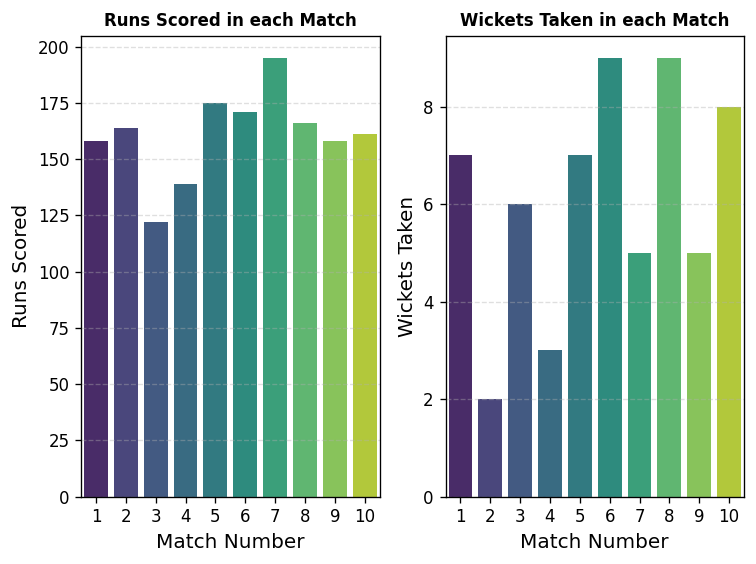

In [15]:
colors = sns.color_palette("coolwarm", len(runs_wickets))

plt.figure(dpi = 120)
plt.subplot(1,2,1)
sns.barplot(x = runs_wickets["Match_No"], y = runs_wickets["Runs_Scored"], palette = "viridis")

plt.xlabel("Match Number", fontsize = 12)
plt.ylabel("Runs Scored", fontsize = 12)
plt.title("Runs Scored in each Match", fontsize=10, fontweight="bold")

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.subplot(1,2,2)
sns.barplot(x = runs_wickets["Match_No"], y = runs_wickets["Wickets_Taken"], palette = "viridis")

plt.xlabel("Match Number", fontsize = 12)
plt.ylabel("Wickets Taken", fontsize = 12)
plt.title("Wickets Taken in each Match", fontsize=10, fontweight="bold")

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Individual Runs Scored by Players

---



In [16]:
done_batting = df2[df2["Balls_Played"]> 0]
runs_difference  = done_batting.groupby("Player_Name").agg({"Runs_Scored": "sum", "Balls_Played": "sum"}).sort_values(by = "Runs_Scored", ascending = False).astype(int).reset_index()
runs_difference.index = runs_difference.index + 1
runs_difference[["Player_Name", "Runs_Scored", "Balls_Played"]]

,Player_Name,Runs_Scored,Balls_Played
1,Vikas Singh,402,238
2,Sameer Patil,291,218
3,Raj Kumar,229,148
4,Arjun Sharma,183,128
5,Dev Rajan,142,97
6,Kiran Naik,118,110
7,Manish Gupta,104,97
8,Nisheet Chand,71,55
9,Suresh Mehta,53,71
10,Anil Gosh,9,11


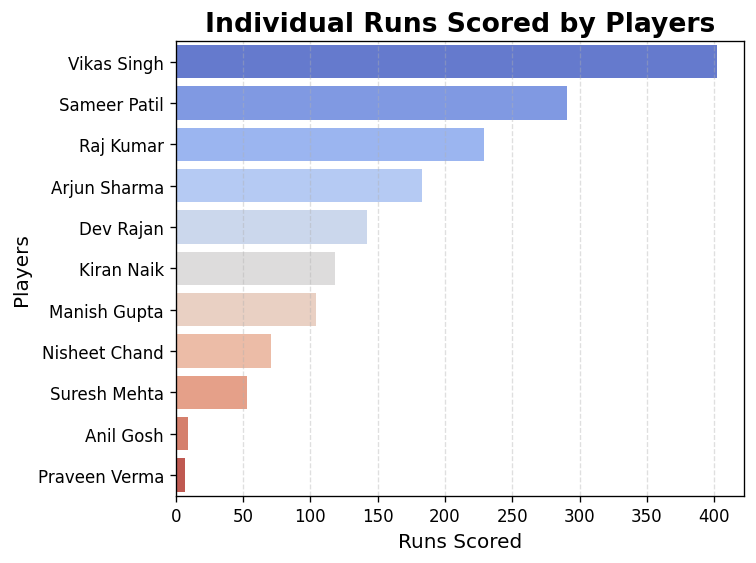

In [17]:
colors = sns.color_palette("coolwarm", len(runs_difference))

# Horizontal barplot
plt.figure(dpi = 120)
sns.barplot(y=runs_difference["Player_Name"], x=runs_difference["Runs_Scored"], palette=colors)

# Titles and labels
plt.title("Individual Runs Scored by Players", fontsize=16, fontweight="bold")
plt.xlabel("Runs Scored", fontsize=12)
plt.ylabel("Players", fontsize=12)

# Gridlines
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Total Runs Contribution

---



In [18]:
top_batters = runs_difference[["Player_Name", "Runs_Scored"]].head().reset_index(drop = True)
other_runs = runs_difference["Runs_Scored"].sum().astype(int) - top_batters["Runs_Scored"].sum().astype(int)
batting_data = top_batters.copy()
batting_data.loc[len(batting_data)] = ["Others", int(other_runs)]
batting_data = batting_data[batting_data["Runs_Scored"] > 0]

In [19]:
batting_data

,Player_Name,Runs_Scored
0,Vikas Singh,402
1,Sameer Patil,291
2,Raj Kumar,229
3,Arjun Sharma,183
4,Dev Rajan,142
5,Others,362


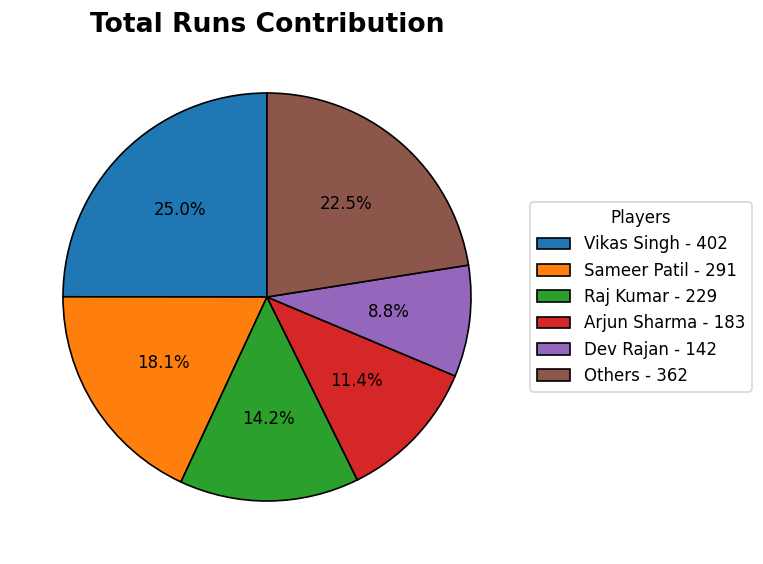

In [20]:
plt.figure(dpi = 120)
wedges, texts, autotexts = plt.pie(batting_data["Runs_Scored"], labels= None, autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "black"})

# Create legend labels with values
legend_labels = [
    f"{player} - {runs}"
    for player, runs in zip(batting_data["Player_Name"], batting_data["Runs_Scored"])
]

plt.legend(wedges, legend_labels, title="Players", loc="center left", bbox_to_anchor=(1, 0.5))

plt.title("Total Runs Contribution", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


Individual Wickets Taken by Players

---



In [21]:
done_bowling = df2[df2["Overs_Bowled"]> 0]
# UPDATED: overs are summed as balls and then converted back to overs
bowling_diff = (done_bowling.groupby("Player_Name", as_index = False).agg(Wickets_Taken=("Wickets_Taken", "sum"), Balls_Bowled=("Balls_Bowled", "sum"))).sort_values(by = "Wickets_Taken",ascending = False).reset_index(drop = True)
bowling_diff["Wickets_Taken"] = bowling_diff["Wickets_Taken"].astype(int)
bowling_diff["Overs_Bowled"] = balls_to_overs(bowling_diff["Balls_Bowled"])
bowling_diff = bowling_diff[["Player_Name", "Wickets_Taken", "Overs_Bowled"]]
bowling_diff.index = bowling_diff.index + 1
bowling_diff

,Player_Name,Wickets_Taken,Overs_Bowled
1,Kiran Naik,16,40.0
2,Suresh Mehta,11,33.0
3,Manish Gupta,10,39.0
4,Nisheet Chand,10,26.0
5,Sameer Patil,8,28.0
6,Dev Rajan,4,15.0
7,Praveen Verma,2,19.0


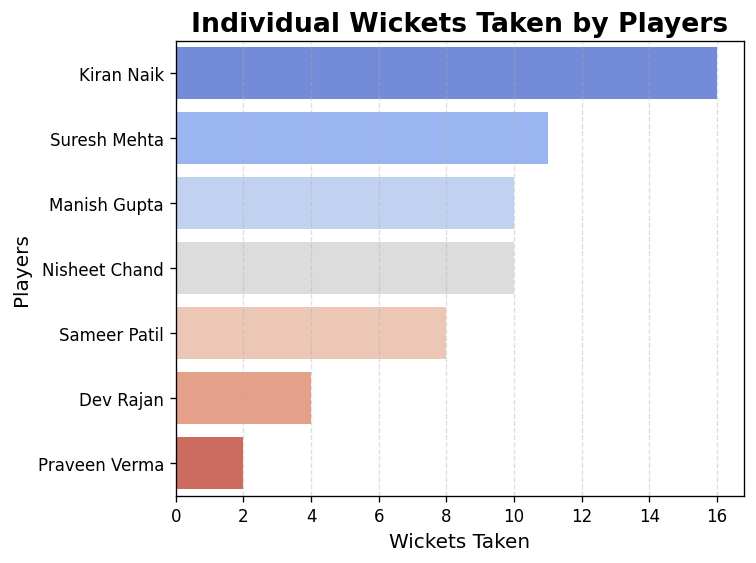

In [22]:
colors = sns.color_palette("coolwarm", len(bowling_diff))

# Horizontal Barplot

plt.figure(dpi = 120)
sns.barplot(x = bowling_diff["Wickets_Taken"], y = bowling_diff["Player_Name"], palette=colors)

# Titles and labels
plt.title("Individual Wickets Taken by Players", fontsize=16, fontweight="bold")
plt.ylabel("Players", fontsize = 12)
plt.xlabel("Wickets Taken", fontsize = 12)

# Gridlines
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Total Wickets Contribution

---



In [23]:
top_bowling = bowling_diff[["Player_Name", "Wickets_Taken"]].head(5).reset_index(drop = True)
other_bowlers = bowling_diff["Wickets_Taken"].sum().astype(int) - top_bowling["Wickets_Taken"].sum().astype(int)
bowling_data = top_bowling.copy().reset_index(drop = "True")
bowling_data.loc[len(bowling_data)] = ["Others", int(other_bowlers)]
bowling_data.index = bowling_data.index + 1
bowling_data = (bowling_data[bowling_data["Wickets_Taken"]>0])
bowling_data

,Player_Name,Wickets_Taken
1,Kiran Naik,16
2,Suresh Mehta,11
3,Manish Gupta,10
4,Nisheet Chand,10
5,Sameer Patil,8
6,Others,6


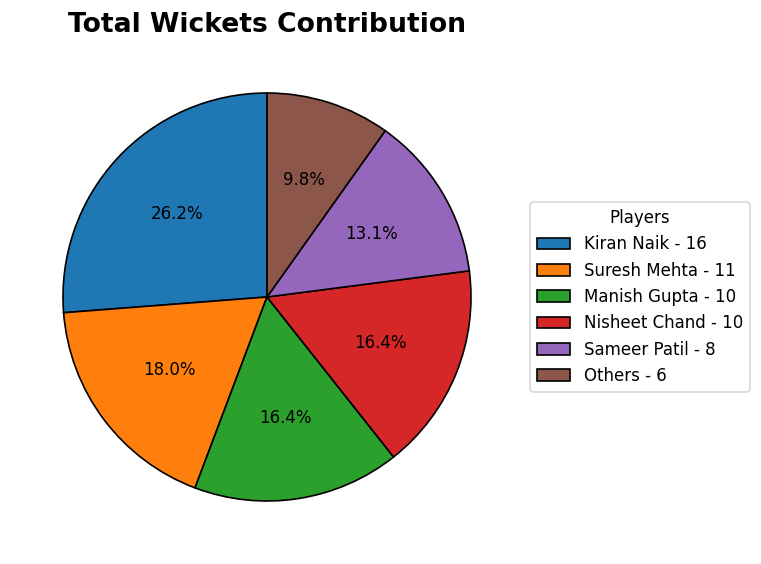

In [24]:
plt.figure(dpi = 120)
wedges, texts, autotexts= plt.pie(bowling_data["Wickets_Taken"], labels= None, autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "black"})

# Create legend labels with values
legend_labels = [
    f"{player} - {wickets}"
    for player, wickets in zip(bowling_data["Player_Name"], bowling_data["Wickets_Taken"])
]

plt.legend(wedges, legend_labels, title="Players", loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Total Wickets Contribution", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

Strike-Rate Comparison between Batsmen and All-Rounders

---



In [25]:
batters_allrounders = done_batting[done_batting["Role"].isin(["batsman", "all-rounder"])]
strike_rate_all = ((batters_allrounders.groupby("Player_Name").agg(Role=("Role", "first"), Strike_Rate=("Strike_Rate", "mean"), Runs_Scored=("Runs_Scored", "sum"), Balls_Played=("Balls_Played", "sum"))).sort_values(by= "Strike_Rate", ascending = False)).round(2).reset_index()

# NEW: only the players who have played 10 or more balls are compared
strike_rate_diff = strike_rate_all[strike_rate_all["Balls_Played"] >= 10].reset_index(drop = True)
strike_rate_diff["Runs_Scored"] = strike_rate_diff["Runs_Scored"].astype(int)
strike_rate_diff["Balls_Played"] = strike_rate_diff["Balls_Played"].astype(int)
strike_rate_diff.index = strike_rate_diff.index + 1

if batters_allrounders.empty:
  print("No batsmen or all-rounders found in the dataset")
strike_rate_diff[["Player_Name", "Role", "Strike_Rate"]]

,Player_Name,Role,Strike_Rate
1,Raj Kumar,batsman,148.89
2,Dev Rajan,all-rounder,143.80
3,Vikas Singh,batsman,141.68
4,Arjun Sharma,batsman,138.32
5,Sameer Patil,all-rounder,125.84
6,Anil Gosh,batsman,45.00


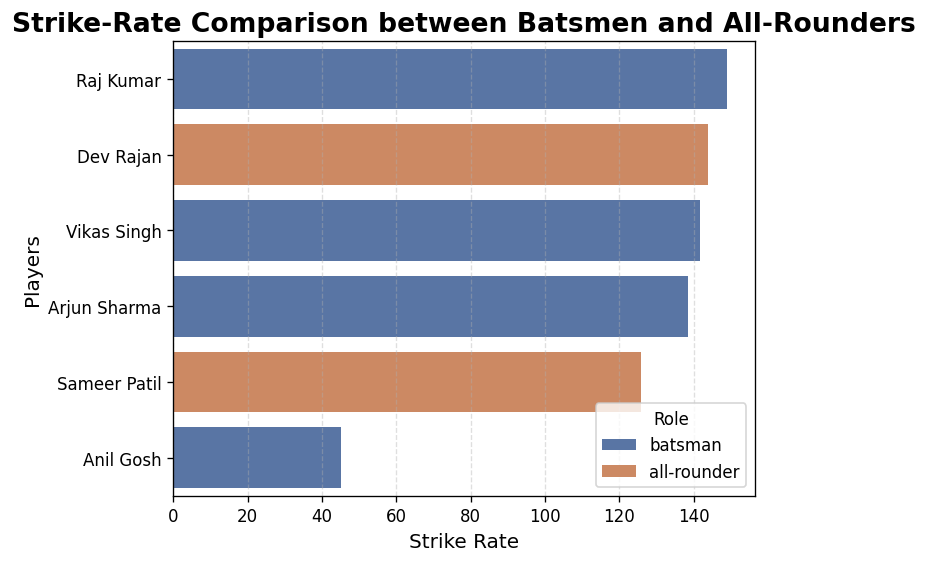

In [26]:
colors = {"batsman": "#4C72B0", "all-rounder": "#DD8452"}

if batters_allrounders.empty:
  print("No batsmen or all-rounders found in the dataset")
else:

  # Horizontal Barplot

  plt.figure(dpi = 120)
  sns.barplot(x = strike_rate_diff["Strike_Rate"], y = strike_rate_diff["Player_Name"], hue = strike_rate_diff["Role"], palette= colors)

  # Titles and labels

  plt.title("Strike-Rate Comparison between Batsmen and All-Rounders", fontsize=16, fontweight="bold")
  plt.xlabel("Strike Rate", fontsize = 12)
  plt.ylabel("Players", fontsize = 12)

  # Gridlines
  plt.grid(axis='x', linestyle='--', alpha=0.4)

  plt.tight_layout()
  plt.show()

Economy-Rate Comparison between Bowlers and All-Rounders


---



In [27]:
bowlers_allrounders = done_bowling[done_bowling["Role"].isin(["bowler", "all-rounder"])]
# UPDATED: balls bowled are used instead of decimal overs
economy_all = ((bowlers_allrounders.groupby("Player_Name", as_index = False).agg(Role=("Role", "first"), Economy_Rate=("Economy_Rate", "mean"), Balls_Bowled=("Balls_Bowled", "sum"), Runs_Given=("Runs_Given", "sum"))).sort_values(by = "Economy_Rate")).round(2).reset_index(drop = True)

# NEW: only the players who have bowled 2 or more overs (12 balls) are compared
economy_diff = economy_all[economy_all["Balls_Bowled"] >= 12].reset_index(drop = True)
economy_diff.index = economy_diff.index + 1

if bowlers_allrounders.empty:
  print("No bowlers or all-rounders found in the dataset")
economy_diff[["Player_Name", "Role", "Economy_Rate"]]

,Player_Name,Role,Economy_Rate
1,Kiran Naik,bowler,5.62
2,Sameer Patil,all-rounder,6.96
3,Dev Rajan,all-rounder,6.98
4,Manish Gupta,bowler,7.22
5,Suresh Mehta,bowler,7.42
6,Nisheet Chand,bowler,7.43
7,Praveen Verma,bowler,9.07


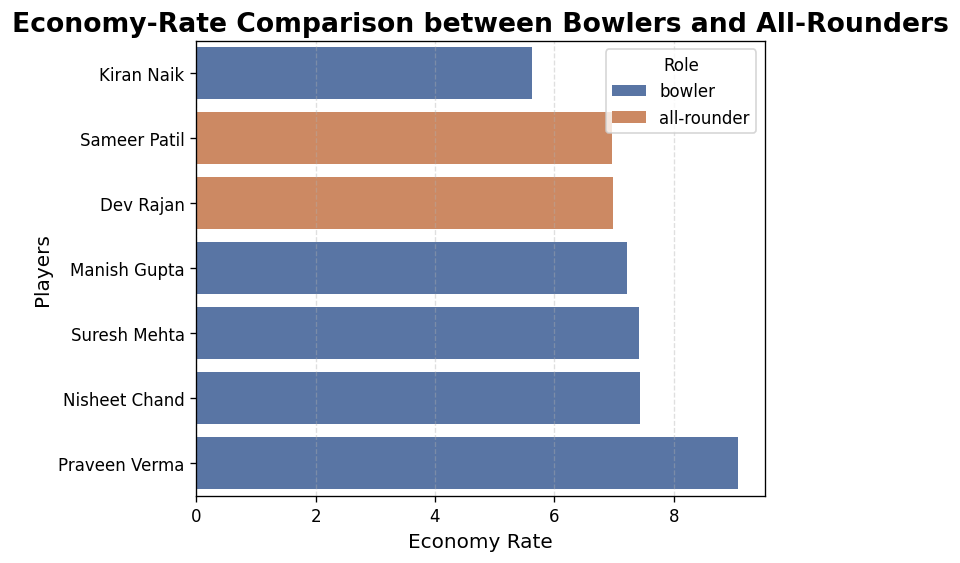

In [28]:
colors = {"bowler": "#4C72B0", "all-rounder": "#DD8452"}

if bowlers_allrounders.empty:
  print("No bowlers or all-rounders found in the dataset")
else:
  #Horizontal Barplot
  plt.figure(dpi = 120)
  sns.barplot(x = economy_diff["Economy_Rate"], y = economy_diff["Player_Name"], hue = economy_diff["Role"], palette= colors)

  #Titles and labels

  plt.title("Economy-Rate Comparison between Bowlers and All-Rounders", fontsize=16, fontweight="bold")
  plt.xlabel("Economy Rate", fontsize = 12)
  plt.ylabel("Players", fontsize = 12)

  # Gridlines
  plt.grid(axis='x', linestyle='--', alpha=0.4)

  plt.tight_layout()
  plt.show()

Runs Scored Contribution Based on Roles

---




In [29]:
runs_contribution_by_role = done_batting[done_batting["Runs_Scored"] > 0]
runs_contribution_by_role = (runs_contribution_by_role.groupby("Role", as_index = False)["Runs_Scored"].sum()).sort_values(by= ["Runs_Scored"], ascending = False).reset_index(drop = True)
runs_contribution_by_role["Runs_Scored"] = runs_contribution_by_role["Runs_Scored"].astype(int)
runs_contribution_by_role.index = runs_contribution_by_role.index + 1
runs_contribution_by_role

,Role,Runs_Scored
1,batsman,823
2,all-rounder,433
3,bowler,353


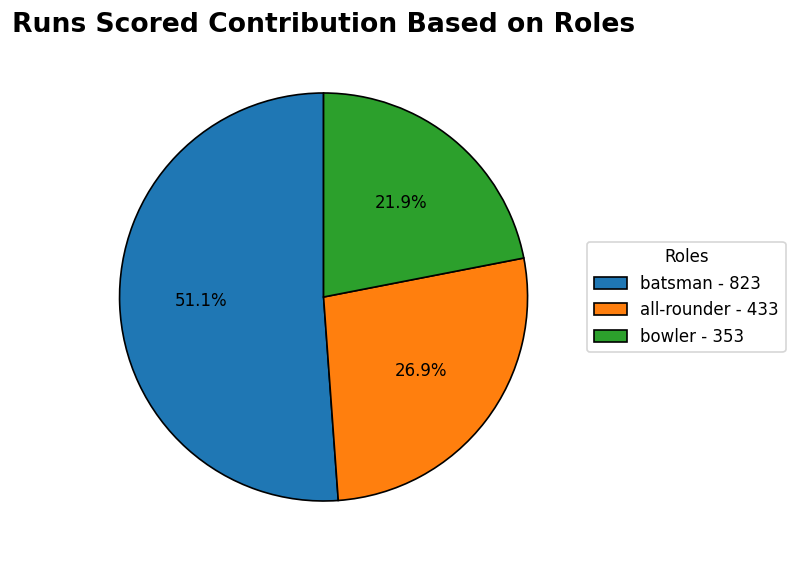

In [30]:
plt.figure(dpi = 120)
wedges, texts, autotexts= plt.pie(runs_contribution_by_role["Runs_Scored"], labels= None, autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "black"})

# Create legend labels with values
legend_labels = [
    f"{role} - {runs}"
    for role, runs in zip(runs_contribution_by_role["Role"], runs_contribution_by_role["Runs_Scored"])
]

plt.legend(wedges, legend_labels, title="Roles", loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Runs Scored Contribution Based on Roles", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

Total Wickets Taken Contribution Based on Roles

---

In [31]:
wickets_contribution_by_role = done_bowling[done_bowling["Wickets_Taken"] > 0]
wickets_contribution_by_role = (wickets_contribution_by_role.groupby("Role", as_index = False)["Wickets_Taken"].sum()).sort_values(by = "Wickets_Taken", ascending = False)
wickets_contribution_by_role["Wickets_Taken"] = wickets_contribution_by_role["Wickets_Taken"].astype(int)
wickets_contribution_by_role.index = wickets_contribution_by_role.index + 1
wickets_contribution_by_role

,Role,Wickets_Taken
2,bowler,49
1,all-rounder,12


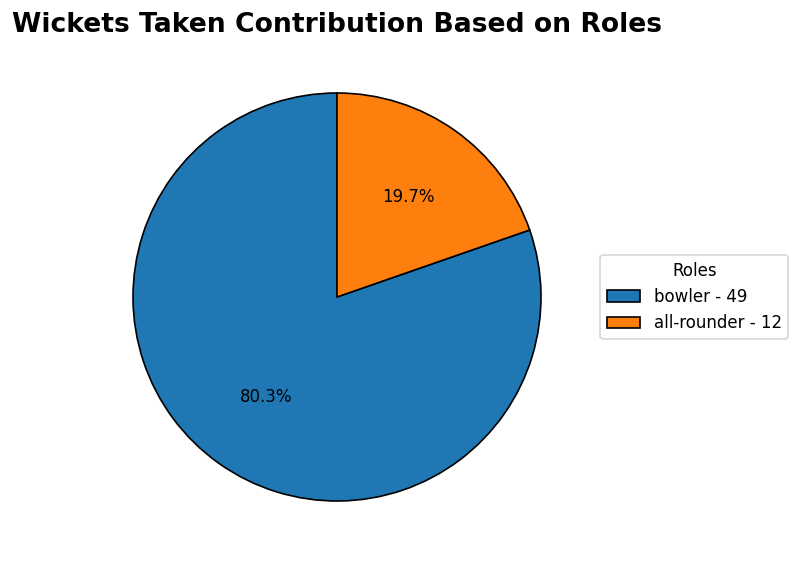

In [32]:
plt.figure(dpi = 120)
wedges, texts, autotexts= plt.pie(wickets_contribution_by_role["Wickets_Taken"], labels= None, autopct="%1.1f%%", startangle=90, wedgeprops= {"edgecolor" : "black"})
plt.title("Wickets Taken Contribution Based on Roles", fontsize=16, fontweight="bold")

# Create legend labels with values
legend_labels = [
    f"{role} - {wickets}"
    for role, wickets in zip(wickets_contribution_by_role["Role"], wickets_contribution_by_role["Wickets_Taken"])
]
plt.legend(wedges, legend_labels, title="Roles", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

NEW - Average Wickets by Role

---


In [33]:
# average wickets per bowling innings (rows where the player actually bowled), by role
wickets_role_avg = done_bowling.groupby("Role", as_index = False)["Wickets_Taken"].mean().round(2).sort_values(by = "Wickets_Taken", ascending = False).reset_index(drop = True)
wickets_role_avg = wickets_role_avg.rename(columns = {"Wickets_Taken": "Average_Wickets_Taken"})
wickets_role_avg.index = wickets_role_avg.index + 1
wickets_role_avg

,Role,Average_Wickets_Taken
1,bowler,1.20
2,all-rounder,1.09


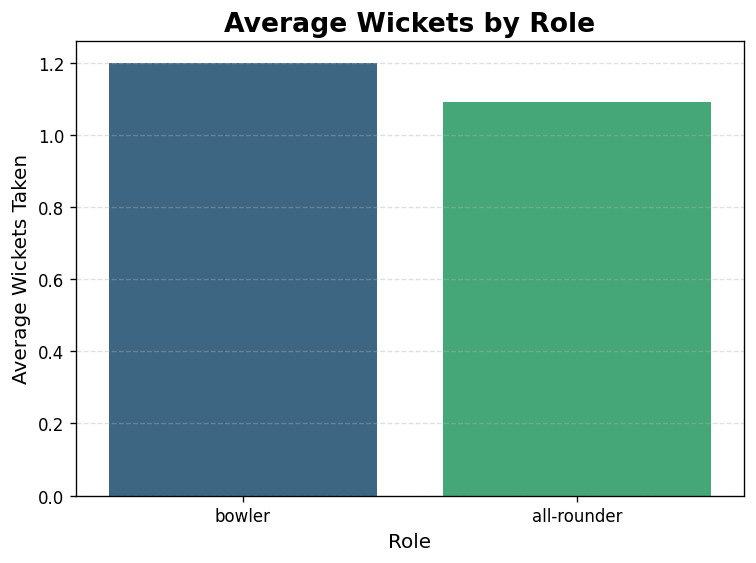

In [34]:
plt.figure(dpi = 120)
sns.barplot(x = wickets_role_avg["Role"], y = wickets_role_avg["Average_Wickets_Taken"], palette = "viridis")

plt.title("Average Wickets by Role", fontsize = 16, fontweight = "bold")
plt.xlabel("Role", fontsize = 12)
plt.ylabel("Average Wickets Taken", fontsize = 12)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Players Consistency in Batting

---


In [35]:
# UPDATED: one common function for batting and bowling consistency
def consistency_table(match_values, value_col):
  table = (match_values.groupby("Player_Name")[value_col].agg(["mean", "std", "count"]).round(2).reset_index())
  table = table[table["count"] > 1].copy()
  table["Consistency_Score"] = (table["mean"] / (table["std"] + 1)).round(2)
  table = table.sort_values(by = "Consistency_Score", ascending = False).reset_index(drop = True)
  table.index = table.index + 1
  return table[["Player_Name", "Consistency_Score"]]

def consistency_state(active_rows, value_col):
  # returns "single" (only 1 match), "unique" (no player appears in more than 1 match) or "ok" with the table
  per_match = active_rows.groupby(["Match_No", "Player_Name"])[value_col].sum().reset_index()
  matches_per_player = active_rows.groupby("Player_Name")["Match_No"].nunique()
  if active_rows["Match_No"].nunique() == 1:
    return "single", None
  if (matches_per_player == 1).all():
    return "unique", None
  return "ok", consistency_table(per_match, value_col)

In [36]:
bat_consistency_state, batting_consistency = consistency_state(done_batting, "Runs_Scored")

if bat_consistency_state == "single":
  print("Players Consistency in Batting is not applicable for single match dataset")
elif bat_consistency_state == "unique":
  # NEW: consistency needs the same player in more than 1 match
  print("The dataset only consists unique players in each match, Players consistency cannot be calculated without same player appearing in multiple matches")
else:
  display(batting_consistency)

,Player_Name,Consistency_Score
1,Sameer Patil,1.29
2,Dev Rajan,1.25
3,Arjun Sharma,1.23
4,Vikas Singh,1.07
5,Raj Kumar,1.03
6,Nisheet Chand,0.98
7,Manish Gupta,0.93
8,Kiran Naik,0.90
9,Suresh Mehta,0.76
10,Anil Gosh,0.61


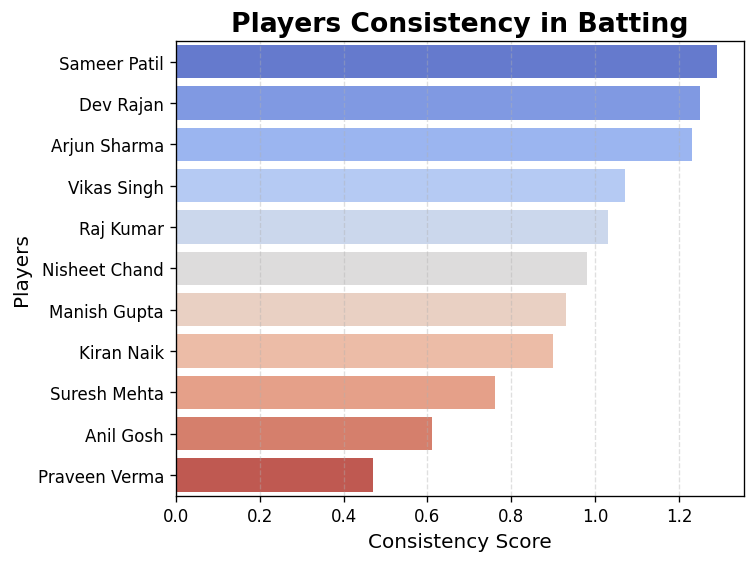

In [37]:
if bat_consistency_state == "ok":
  colors = sns.color_palette("coolwarm", len(batting_consistency))

  #Horizontal Barplot
  plt.figure(dpi = 120)
  sns.barplot(y = batting_consistency["Player_Name"], x = batting_consistency["Consistency_Score"], palette= colors)

  #Titles and labels
  plt.title("Players Consistency in Batting", fontsize=16, fontweight="bold")
  plt.ylabel("Players", fontsize = 12)
  plt.xlabel("Consistency Score", fontsize = 12)

  # Gridlines
  plt.grid(axis='x', linestyle='--', alpha=0.4)

  plt.tight_layout()
  plt.show()
else:
  print("Players Consistency in Batting can't be plotted for this dataset")

Players Consistency in Bowling

---



In [38]:
bowl_consistency_state, bowling_consistency = consistency_state(done_bowling, "Wickets_Taken")

if bowl_consistency_state == "single":
  print("Players Consistency in Bowling is not applicable for single match dataset")
elif bowl_consistency_state == "unique":
  print("The dataset only consists unique players in each match, Players consistency cannot be calculated without same player appearing in multiple matches")
else:
  display(bowling_consistency)

,Player_Name,Consistency_Score
1,Kiran Naik,0.81
2,Suresh Mehta,0.67
3,Nisheet Chand,0.63
4,Sameer Patil,0.55
5,Dev Rajan,0.55
6,Manish Gupta,0.52
7,Praveen Verma,0.26


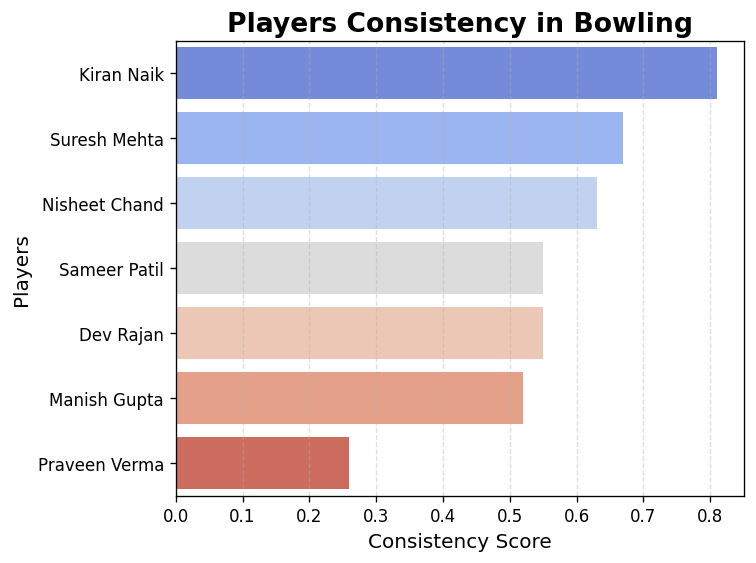

In [39]:
if bowl_consistency_state == "ok":
  colors = sns.color_palette("coolwarm", len(bowling_consistency))

  #Horizontal Barplot

  plt.figure(dpi = 120)
  sns.barplot(y = bowling_consistency["Player_Name"], x = bowling_consistency["Consistency_Score"], palette= colors)

  #Titles and labels

  plt.title("Players Consistency in Bowling", fontsize=16, fontweight="bold")
  plt.xlabel("Consistency Score", fontsize = 12)
  plt.ylabel("Players", fontsize = 12)

  # Gridlines
  plt.grid(axis='x', linestyle='--', alpha=0.4)

  plt.tight_layout()
  plt.show()
else:
  print("Players Consistency in Bowling can't be plotted for this dataset")

Total Runs by Batting Order

---


In [40]:
# UPDATED: earlier this was named "Average" but it was the total, so it is renamed to Total_Runs_Scored
order_runs = df2.groupby("Batting_Order", as_index = False)["Runs_Scored"].sum().sort_values(by = "Runs_Scored", ascending = False).reset_index(drop = True)
order_runs = order_runs.rename(columns = {"Runs_Scored": "Total_Runs_Scored"})
order_runs.index += 1
order_runs

,Batting_Order,Total_Runs_Scored
1,top,814.0
2,middle,655.0
3,lower,140.0


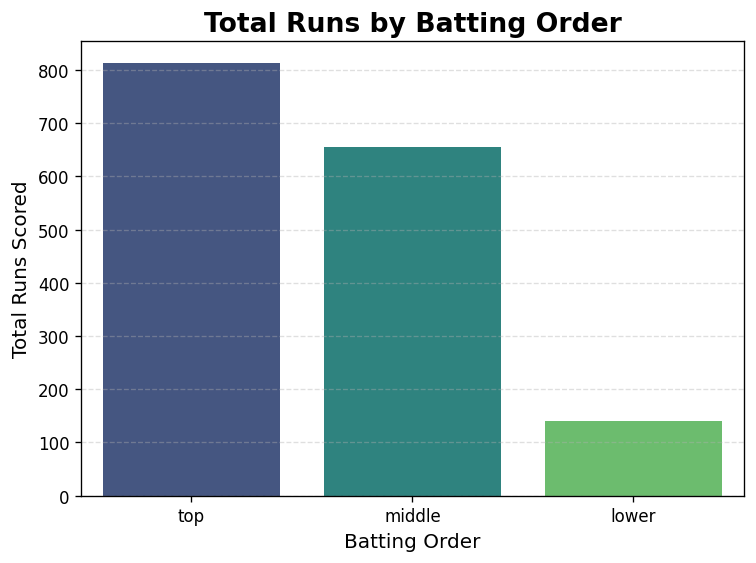

In [41]:
# UPDATED: plotted for single match also
plt.figure(dpi=120)

sns.barplot(x= order_runs["Batting_Order"], y= order_runs["Total_Runs_Scored"], palette = "viridis")

plt.title("Total Runs by Batting Order", fontsize = 16, fontweight = "bold")
plt.xlabel("Batting Order", fontsize = 12)
plt.ylabel("Total Runs Scored", fontsize = 12)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

NEW - Average Runs by Batting Order

---


In [42]:
# average runs per batting innings (rows where the player actually batted)
order_avg_runs = done_batting.groupby("Batting_Order", as_index = False)["Runs_Scored"].mean().round(2).sort_values(by = "Runs_Scored", ascending = False).reset_index(drop = True)
order_avg_runs = order_avg_runs.rename(columns = {"Runs_Scored": "Average_Runs_Scored"})
order_avg_runs.index += 1
order_avg_runs

,Batting_Order,Average_Runs_Scored
1,top,27.13
2,middle,17.24
3,lower,6.09


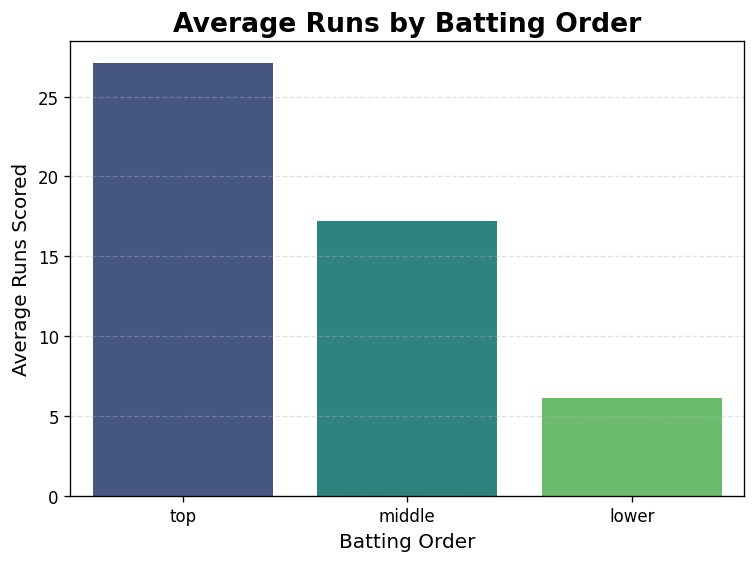

In [43]:
plt.figure(dpi=120)

sns.barplot(x= order_avg_runs["Batting_Order"], y= order_avg_runs["Average_Runs_Scored"], palette = "viridis")

plt.title("Average Runs by Batting Order", fontsize = 16, fontweight = "bold")
plt.xlabel("Batting Order", fontsize = 12)
plt.ylabel("Average Runs Scored", fontsize = 12)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Phase wise Wickets Lost breakdown

---



In [44]:
# Out_Over is already numeric after cleaning, Was_Out is True only for the dismissed players
wickets_df = df2[df2["Was_Out"] == True].copy()
overs_out = wickets_df["Out_Over"]

# Powerplay : upto 6 overs, Middle Overs : upto 15 overs, rest are Death Overs
wickets_df["Wicket_Phase"] = np.select([overs_out <= 6, overs_out <= 15], ["Powerplay", "Middle Overs"], default = "Death Overs")

# UPDATED: phases with no wickets are shown with 0 instead of NaN
phase_order = ["Powerplay", "Middle Overs", "Death Overs"]
phase_wickets = wickets_df["Wicket_Phase"].value_counts().reindex(phase_order, fill_value = 0).rename_axis("Wicket_Phase").reset_index(name = "Wickets_Lost").sort_values(by = "Wickets_Lost", ascending = False, kind = "stable")
phase_wickets

,Wicket_Phase,Wickets_Lost
1,Middle Overs,36
0,Powerplay,18
2,Death Overs,18


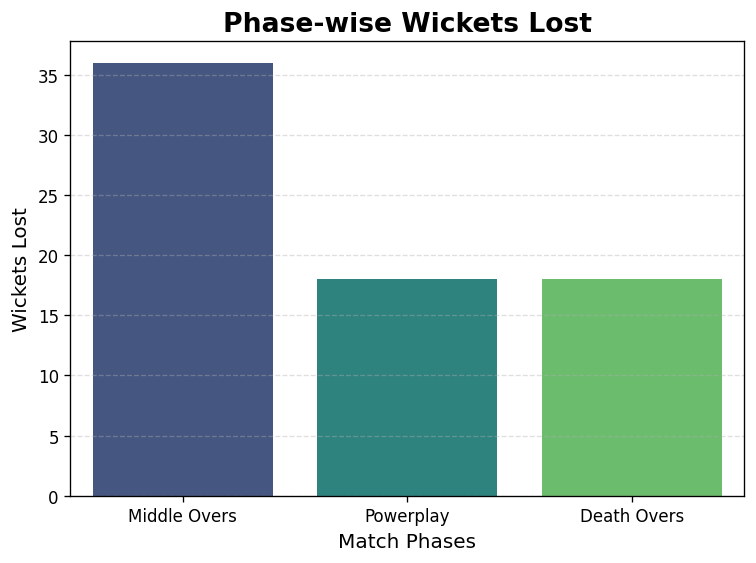

In [45]:
plt.figure(dpi = 120)
sns.barplot(x=phase_wickets["Wicket_Phase"],y=phase_wickets["Wickets_Lost"], palette = "viridis")

plt.title("Phase-wise Wickets Lost", fontsize = 16, fontweight = "bold")
plt.xlabel("Match Phases", fontsize = 12)
plt.ylabel("Wickets Lost", fontsize = 12)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Player's Total Runs in Each Match

---



In [46]:
if done_batting["Match_No"].nunique() > 1:
  players_list = done_batting["Player_Name"].unique().tolist()
  print("Enter the Player's Index to see the Total Runs Scored by that player in each match")
  for index, player in enumerate(players_list) :
    print(f"{index+1} : {player}")
  player_index = int(input("enter your choice : "))
  selected_player = players_list[player_index - 1]
  selected_player_df = done_batting[done_batting["Player_Name"] == selected_player]
  print(f"{selected_player}'s Total Runs in Each Match")
  player_runs = selected_player_df.groupby("Match_No")["Runs_Scored"].sum().reset_index().sort_values("Match_No")
  player_runs["Runs_Scored"] =  player_runs["Runs_Scored"].astype(int)
  player_runs.index += 1
  print()
  display(player_runs)
else :
  print("Players Total Runs in Each Match is not applicable for single match dataset.")

Enter the Player's Index to see the Total Runs Scored by that player in each match
1 : Raj Kumar
2 : Vikas Singh
3 : Arjun Sharma
4 : Sameer Patil
5 : Dev Rajan
6 : Kiran Naik
7 : Manish Gupta
8 : Suresh Mehta
9 : Nisheet Chand
10 : Praveen Verma
11 : Anil Gosh
enter your choice : 1
Raj Kumar's Total Runs in Each Match



,Match_No,Runs_Scored
1,1,11
2,2,58
3,3,0
4,4,6
5,5,59
6,6,28
7,7,13
8,8,16
9,9,6
10,10,32


Enter the Player's Index to see the Total Runs Scored by that player in each match
1 : Raj Kumar
2 : Vikas Singh
3 : Arjun Sharma
4 : Sameer Patil
5 : Dev Rajan
6 : Kiran Naik
7 : Manish Gupta
8 : Suresh Mehta
9 : Nisheet Chand
10 : Praveen Verma
11 : Anil Gosh
enter your choice : 1
Raj Kumar's Total Runs in Each Match



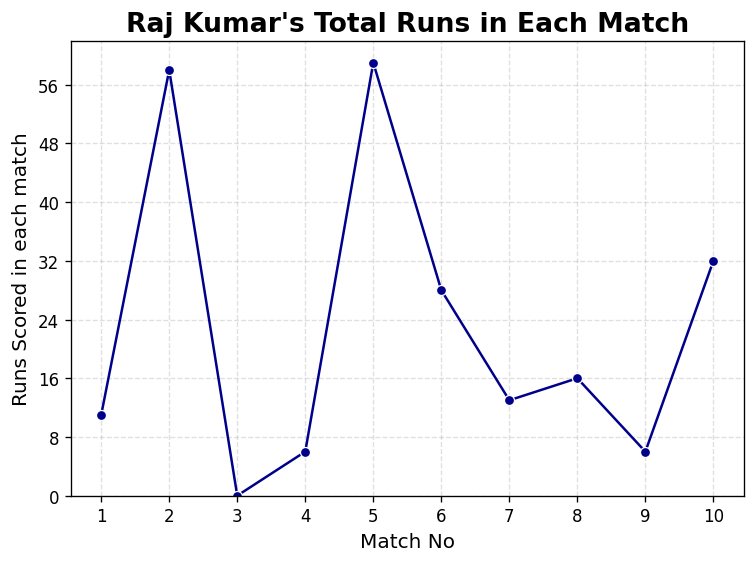

In [47]:
if done_batting["Match_No"].nunique() > 1:
  players_list = done_batting["Player_Name"].unique().tolist()
  print("Enter the Player's Index to see the Total Runs Scored by that player in each match")
  for index, player in enumerate(players_list) :
    print(f"{index+1} : {player}")
  player_index = int(input("enter your choice : "))
  selected_player = players_list[player_index - 1]
  selected_player_df = done_batting[done_batting["Player_Name"] == selected_player]
  print(f"{selected_player}'s Total Runs in Each Match")
  player_runs = selected_player_df.groupby("Match_No")["Runs_Scored"].sum().reset_index().sort_values("Match_No")
  print()

  x_vals = player_runs["Match_No"].astype(int)
  y_vals = player_runs["Runs_Scored"]

  plt.figure(dpi = 120)
  sns.lineplot(x=x_vals, y=y_vals, marker="o", color = "darkblue")

  plt.xticks(x_vals.tolist())
  # UPDATED: evenly spaced whole number ticks and zero baseline instead of one tick for every value
  plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
  plt.ylim(bottom=0)
  plt.title(f"{selected_player}'s Total Runs in Each Match", fontsize = 16, fontweight = "bold")
  plt.xlabel("Match No", fontsize = 12)
  plt.ylabel("Runs Scored in each match", fontsize = 12)

  plt.grid(linestyle='--', alpha=0.4)

  plt.tight_layout()
  plt.show()
else :
  print("Players Total Runs in Each Match is not applicable for single match dataset.")

Player's Total Wickets in Each Match

---



In [48]:
if done_bowling["Match_No"].nunique() > 1:
  players_list_bowl = done_bowling["Player_Name"].unique().tolist()
  print("Enter the Player's Index to see the Total Wickets taken by that player in each match")
  for index, player in enumerate(players_list_bowl) :
    print(f"{index+1} : {player}")
  player_index_bowl = int(input("enter your choice : "))
  selected_player_bowl = players_list_bowl[player_index_bowl - 1]
  selected_player_bowl_df = done_bowling[done_bowling["Player_Name"] == selected_player_bowl]
  print(f"{selected_player_bowl}'s Total Wickets in Each Match")
  player_wickets = selected_player_bowl_df.groupby("Match_No")["Wickets_Taken"].sum().reset_index().sort_values("Match_No")
  player_wickets["Wickets_Taken"] = player_wickets["Wickets_Taken"].astype(int)
  player_wickets.index += 1
  print()
  display(player_wickets)
else :
  print("Player's Total Wickets in Each Match is not applicable for single match dataset.")

Enter the Player's Index to see the Total Wickets taken by that player in each match
1 : Sameer Patil
2 : Kiran Naik
3 : Manish Gupta
4 : Suresh Mehta
5 : Nisheet Chand
6 : Praveen Verma
7 : Dev Rajan
enter your choice : 1
Sameer Patil's Total Wickets in Each Match



,Match_No,Wickets_Taken
1,1,0
2,2,0
3,3,2
4,4,0
5,8,2
6,9,2
7,10,2


Enter the Player's Index to see the Total Wickets taken by that player in each match
1 : Sameer Patil
2 : Kiran Naik
3 : Manish Gupta
4 : Suresh Mehta
5 : Nisheet Chand
6 : Praveen Verma
7 : Dev Rajan
enter your choice : 1
Sameer Patil's Total Wickets in Each Match



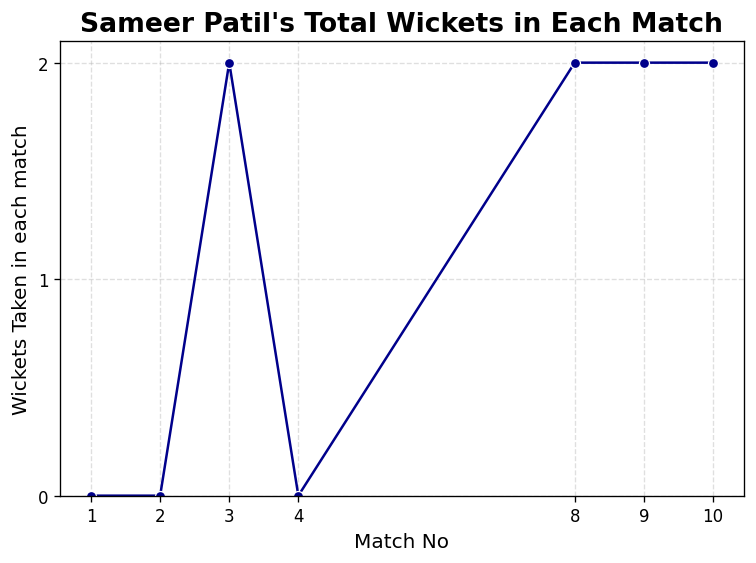

In [49]:
if done_bowling["Match_No"].nunique() > 1:
    players_list_bowl = done_bowling["Player_Name"].unique().tolist()
    print("Enter the Player's Index to see the Total Wickets taken by that player in each match")

    for index, player in enumerate(players_list_bowl):
        print(f"{index+1} : {player}")
    player_index_bowl = int(input("enter your choice : "))
    selected_player_bowl = players_list_bowl[player_index_bowl - 1]
    selected_player_bowl_df = done_bowling[done_bowling["Player_Name"] == selected_player_bowl]
    print(f"{selected_player_bowl}'s Total Wickets in Each Match")
    print()
    player_wickets = (selected_player_bowl_df.groupby("Match_No")["Wickets_Taken"].sum().reset_index().sort_values("Match_No"))

    x_vals = player_wickets["Match_No"].astype(int)
    y_vals = player_wickets["Wickets_Taken"].astype(int)

    plt.figure(dpi=120)
    sns.lineplot(x=x_vals, y=y_vals, marker="o", color = "darkblue")

    plt.xticks(x_vals.tolist())
    # UPDATED: evenly spaced whole number ticks and zero baseline (earlier x values were used for y ticks by mistake)
    plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
    plt.ylim(bottom=0)

    plt.title(f"{selected_player_bowl}'s Total Wickets in Each Match", fontsize = 16, fontweight = "bold")
    plt.xlabel("Match No", fontsize = 12)
    plt.ylabel("Wickets Taken in each match", fontsize = 12)

    plt.grid(linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()

else:
    print("Player's Total Wickets in Each Match is not applicable for single match dataset.")

***Player Analytics***

NEW section - individual batting and bowling performance of one selected player across all matches

---


Per player, per match totals

---


In [50]:
player_match = (df2.groupby(["Player_Name", "Match_No"], as_index = False)
                .agg(Runs_Scored=("Runs_Scored", "sum"), Balls_Played=("Balls_Played", "sum"),
                     Wickets_Taken=("Wickets_Taken", "sum"), Runs_Given=("Runs_Given", "sum"),
                     Balls_Bowled=("Balls_Bowled", "sum"))
                .sort_values(["Player_Name", "Match_No"]))
for col in ["Runs_Scored", "Balls_Played", "Wickets_Taken", "Runs_Given"]:
  player_match[col] = player_match[col].astype(int)
player_match["Match_No"] = player_match["Match_No"].astype(int)
player_match.head()

,Player_Name,Match_No,Runs_Scored,Balls_Played,Wickets_Taken,Runs_Given,Balls_Bowled
0,Anil Gosh,1,0,0,0,0,0
1,Anil Gosh,2,0,0,0,0,0
2,Anil Gosh,3,0,1,0,0,0
3,Anil Gosh,4,0,0,0,0,0
4,Anil Gosh,5,0,0,0,0,0


Select the player and Player's Information

---


In [51]:
analytics_players = sorted(df2["Player_Name"].unique())
print("Enter the Player's Index to see the Player Analytics")
for index, name in enumerate(analytics_players) :
  print(f"{index+1} : {name}")
analytics_index = int(input("enter your choice : "))
player = analytics_players[analytics_index - 1]

player_df = df2[df2["Player_Name"] == player]
pm = player_match[player_match["Player_Name"] == player].reset_index(drop = True)

# role is the most common role of the player
role = player_df["Role"].mode().iloc[0]
matches_played = player_df["Match_No"].nunique()

# usual batting order is decided from the average batting position
avg_position = int(round(player_df["Batting_Position"].mean()))
order_label = "top" if avg_position <= 3 else "middle" if avg_position <= 7 else "lower"

has_batted = (pm["Balls_Played"] > 0).any()
has_bowled = (pm["Balls_Bowled"] > 0).any()
total_runs = int(pm["Runs_Scored"].sum())
total_wickets = int(pm["Wickets_Taken"].sum())

print(f"{player}'s Information")
print(f"1. Selected player is a {role.title()}, based on the role they have.")
print(f"2. The player has played {matches_played} match(es).")
print(f"3. Usually bats at the {order_label} order.")
if has_batted:
  print(f"4. The player has scored {total_runs} runs.")
if has_bowled:
  print(f"5. The player has taken {total_wickets} wickets.")

Enter the Player's Index to see the Player Analytics
1 : Anil Gosh
2 : Arjun Sharma
3 : Dev Rajan
4 : Kiran Naik
5 : Manish Gupta
6 : Nisheet Chand
7 : Praveen Verma
8 : Raj Kumar
9 : Sameer Patil
10 : Suresh Mehta
11 : Vikas Singh
enter your choice : 1
Anil Gosh's Information
1. Selected player is a Batsman, based on the role they have.
2. The player has played 10 match(es).
3. Usually bats at the lower order.
4. The player has scored 9 runs.


Player's Individual Batting Stats

---


In [52]:
if not has_batted:
  print("The player has not done batting in any match, so we cannot present the batting insights for selected player.")
else:
  mb = pm[["Match_No", "Runs_Scored", "Balls_Played"]].copy()
  mb["Strike_Rate"] = np.where(mb["Balls_Played"] > 0, mb["Runs_Scored"] / mb["Balls_Played"].where(mb["Balls_Played"] > 0, 1) * 100, 0.0).round(2)
  mb.index = mb.index + 1

  # consistency is calculated only on the matches where the player batted
  batted = mb[mb["Balls_Played"] > 0]
  bat_consistency = round(batted["Runs_Scored"].mean() / (batted["Runs_Scored"].std() + 1), 2) if len(batted) > 1 else None
  total_balls = int(mb["Balls_Played"].sum())
  overall_sr = round((total_runs / total_balls) * 100, 2) if total_balls > 0 else 0.0

  print(f"Total Runs : {total_runs}")
  print(f"Balls Played : {total_balls}")
  print(f"Strike Rate : {overall_sr}")
  print(f"Batting Consistency : {bat_consistency if bat_consistency is not None else 'N/A'}")
  print()
  display(mb)

Total Runs : 9
Balls Played : 11
Strike Rate : 81.82
Batting Consistency : 0.61



,Match_No,Runs_Scored,Balls_Played,Strike_Rate
1,1,0,0,0.0
2,2,0,0,0.0
3,3,0,1,0.0
4,4,0,0,0.0
5,5,0,0,0.0
6,6,0,0,0.0
7,7,9,10,90.0
8,8,0,0,0.0
9,9,0,0,0.0
10,10,0,0,0.0


Player's Runs in Each Match

---


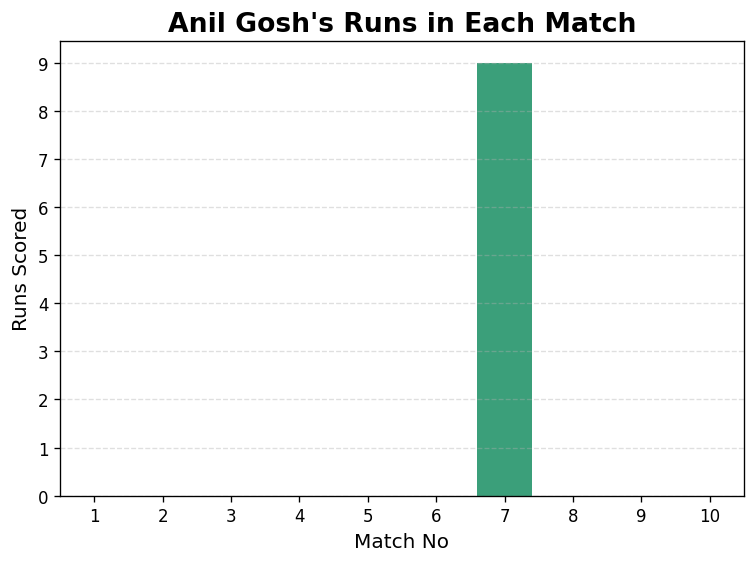

In [53]:
if has_batted:
  match_nos = mb["Match_No"].astype(int)

  plt.figure(dpi = 120)
  sns.barplot(x = match_nos, y = mb["Runs_Scored"], palette = "viridis")
  plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

  plt.title(f"{player}'s Runs in Each Match", fontsize=16, fontweight="bold")
  plt.xlabel("Match No", fontsize=12)
  plt.ylabel("Runs Scored", fontsize=12)

  plt.grid(axis='y', linestyle='--', alpha=0.4)

  plt.tight_layout()
  plt.show()
else:
  print("The player has not done batting in any match")

Player's Strike Rate in Each Match

---


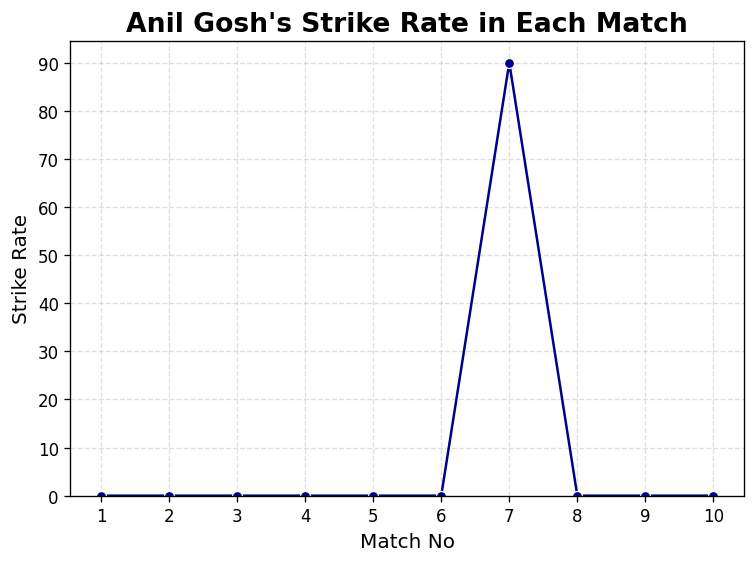

In [54]:
if has_batted:
  match_nos = mb["Match_No"].astype(int)

  plt.figure(dpi = 120)
  sns.lineplot(x = match_nos, y = mb["Strike_Rate"], marker="o", color = "darkblue")

  plt.xticks(match_nos.tolist())
  plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
  plt.ylim(bottom=0)

  plt.title(f"{player}'s Strike Rate in Each Match", fontsize=16, fontweight="bold")
  plt.xlabel("Match No", fontsize=12)
  plt.ylabel("Strike Rate", fontsize=12)

  plt.grid(linestyle='--', alpha=0.4)

  plt.tight_layout()
  plt.show()
else:
  print("The player has not done batting in any match")

Player's Runs Contribution in a Match

---


Enter the Match Number to see the player's runs contribution in that match
Matches :  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
enter your choice : 1


,Label,Runs
1,Others,158


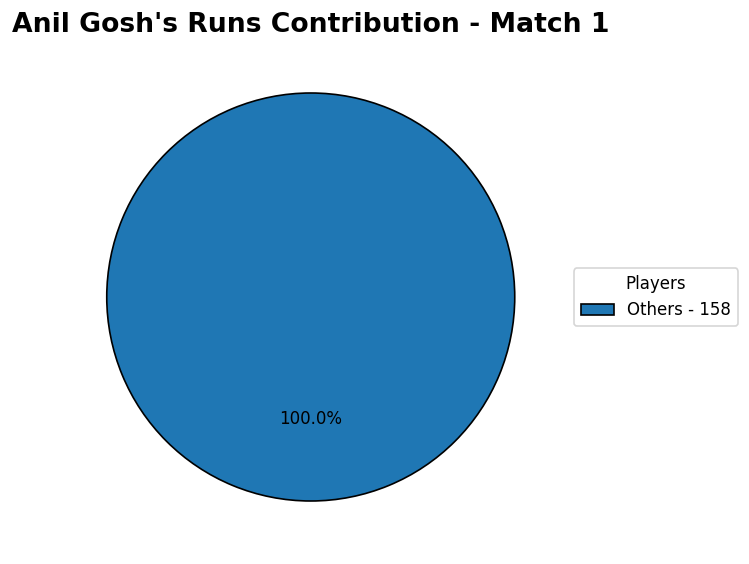

In [55]:
if has_batted:
  print("Enter the Match Number to see the player's runs contribution in that match")
  print("Matches : ", [int(m) for m in sorted(mb["Match_No"].unique())])
  selected_match = int(input("enter your choice : "))

  # team runs of that match, counting only the players who batted
  match_rows = player_match[player_match["Match_No"] == selected_match]
  match_rows = match_rows[match_rows["Balls_Played"] > 0]
  team_runs = int(match_rows["Runs_Scored"].sum())
  player_match_runs = int(match_rows.loc[match_rows["Player_Name"] == player, "Runs_Scored"].sum())

  pie_df = pd.DataFrame({"Label": [player, "Others"], "Runs": [player_match_runs, team_runs - player_match_runs]})
  pie_df = pie_df[pie_df["Runs"] > 0]

  if pie_df.empty:
    print(f"{player} did not score any runs in Match {selected_match}.")
  else:
    display(pie_df)

    plt.figure(dpi = 120)
    wedges, texts, autotexts = plt.pie(pie_df["Runs"], labels= None, autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "black"})

    # Create legend labels with values
    legend_labels = [f"{label} - {runs}" for label, runs in zip(pie_df["Label"], pie_df["Runs"])]

    plt.legend(wedges, legend_labels, title="Players", loc="center left", bbox_to_anchor=(1, 0.5))
    plt.title(f"{player}'s Runs Contribution - Match {selected_match}", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
  print("The player has not done batting in any match")

Player's Run Contribution Against the Team

---


,Label,Runs
0,Anil Gosh,9
1,Others,1600


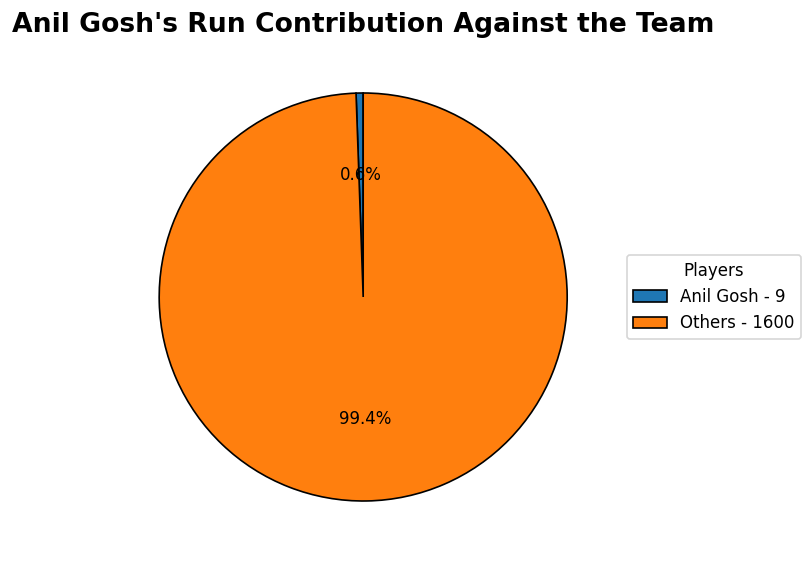

In [56]:
if has_batted:
  # team total runs across all matches, counting only the players who batted
  team_total_runs = int(player_match.loc[player_match["Balls_Played"] > 0, "Runs_Scored"].sum())

  pie_df = pd.DataFrame({"Label": [player, "Others"], "Runs": [total_runs, team_total_runs - total_runs]})
  pie_df = pie_df[pie_df["Runs"] > 0]

  if pie_df.empty:
    print(f"{player} has not scored any runs across all matches.")
  else:
    display(pie_df)

    plt.figure(dpi = 120)
    wedges, texts, autotexts = plt.pie(pie_df["Runs"], labels= None, autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "black"})

    # Create legend labels with values
    legend_labels = [f"{label} - {runs}" for label, runs in zip(pie_df["Label"], pie_df["Runs"])]

    plt.legend(wedges, legend_labels, title="Players", loc="center left", bbox_to_anchor=(1, 0.5))
    plt.title(f"{player}'s Run Contribution Against the Team", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
  print("The player has not done batting in any match")

Player's Individual Bowling Stats

---


In [57]:
if not has_bowled:
  print("The player has not done bowling in any match, so we cannot present the bowling insights for selected player.")
else:
  mw = pm[["Match_No", "Wickets_Taken", "Runs_Given", "Balls_Bowled"]].copy()
  mw["Overs_Bowled"] = balls_to_overs(mw["Balls_Bowled"])
  mw["Economy_Rate"] = np.where(mw["Balls_Bowled"] > 0, mw["Runs_Given"] / (mw["Balls_Bowled"].where(mw["Balls_Bowled"] > 0, 1) / 6), 0.0).round(2)
  mw.index = mw.index + 1

  # consistency is calculated only on the matches where the player bowled
  bowled = mw[mw["Balls_Bowled"] > 0]
  bowl_consistency = round(bowled["Wickets_Taken"].mean() / (bowled["Wickets_Taken"].std() + 1), 2) if len(bowled) > 1 else None
  total_balls_bowled = int(mw["Balls_Bowled"].sum())
  total_overs = float(balls_to_overs(total_balls_bowled))
  overall_eco = round(float(mw["Runs_Given"].sum()) / (total_balls_bowled / 6), 2) if total_balls_bowled > 0 else 0.0

  print(f"Total Wickets : {total_wickets}")
  print(f"Overs Bowled : {total_overs}")
  print(f"Economy Rate : {overall_eco}")
  print(f"Bowling Consistency : {bowl_consistency if bowl_consistency is not None else 'N/A'}")
  print()
  display(mw)

The player has not done bowling in any match, so we cannot present the bowling insights for selected player.


Player's Wickets in Each Match

---


In [58]:
if has_bowled:
  match_nos = mw["Match_No"].astype(int)

  plt.figure(dpi = 120)
  sns.barplot(x = match_nos, y = mw["Wickets_Taken"], palette = "viridis")
  plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

  plt.title(f"{player}'s Wickets in Each Match", fontsize=16, fontweight="bold")
  plt.xlabel("Match No", fontsize=12)
  plt.ylabel("Wickets Taken", fontsize=12)

  plt.grid(axis='y', linestyle='--', alpha=0.4)

  plt.tight_layout()
  plt.show()
else:
  print("The player has not done bowling in any match")

The player has not done bowling in any match


Player's Economy Rate in Each Match

---


In [59]:
if has_bowled:
  match_nos = mw["Match_No"].astype(int)

  plt.figure(dpi = 120)
  sns.lineplot(x = match_nos, y = mw["Economy_Rate"], marker="o", color = "darkblue")

  plt.xticks(match_nos.tolist())
  plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
  plt.ylim(bottom=0)

  plt.title(f"{player}'s Economy Rate in Each Match", fontsize=16, fontweight="bold")
  plt.xlabel("Match No", fontsize=12)
  plt.ylabel("Economy Rate", fontsize=12)

  plt.grid(linestyle='--', alpha=0.4)

  plt.tight_layout()
  plt.show()
else:
  print("The player has not done bowling in any match")

The player has not done bowling in any match


Player's Wickets Contribution in a Match

---


In [60]:
if has_bowled:
  print("Enter the Match Number to see the player's wickets contribution in that match")
  print("Matches : ", [int(m) for m in sorted(mw["Match_No"].unique())])
  selected_match_bowl = int(input("enter your choice : "))

  # team wickets of that match, counting only the players who bowled
  match_rows = player_match[player_match["Match_No"] == selected_match_bowl]
  match_rows = match_rows[match_rows["Balls_Bowled"] > 0]
  team_wkts = int(match_rows["Wickets_Taken"].sum())
  player_match_wkts = int(match_rows.loc[match_rows["Player_Name"] == player, "Wickets_Taken"].sum())

  pie_df = pd.DataFrame({"Label": [player, "Others"], "Wickets": [player_match_wkts, team_wkts - player_match_wkts]})
  pie_df = pie_df[pie_df["Wickets"] > 0]

  if pie_df.empty:
    print(f"{player} did not take any wickets in Match {selected_match_bowl}.")
  else:
    display(pie_df)

    plt.figure(dpi = 120)
    wedges, texts, autotexts = plt.pie(pie_df["Wickets"], labels= None, autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "black"})

    # Create legend labels with values
    legend_labels = [f"{label} - {wkts}" for label, wkts in zip(pie_df["Label"], pie_df["Wickets"])]

    plt.legend(wedges, legend_labels, title="Players", loc="center left", bbox_to_anchor=(1, 0.5))
    plt.title(f"{player}'s Wickets Contribution - Match {selected_match_bowl}", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
  print("The player has not done bowling in any match")

The player has not done bowling in any match


Player's Wicket Contribution Against the Team

---


In [61]:
if has_bowled:
  # team total wickets across all matches, counting only the players who bowled
  team_total_wkts = int(player_match.loc[player_match["Balls_Bowled"] > 0, "Wickets_Taken"].sum())

  pie_df = pd.DataFrame({"Label": [player, "Others"], "Wickets": [total_wickets, team_total_wkts - total_wickets]})
  pie_df = pie_df[pie_df["Wickets"] > 0]

  if pie_df.empty:
    print(f"{player} has not taken any wickets across all matches.")
  else:
    display(pie_df)

    plt.figure(dpi = 120)
    wedges, texts, autotexts = plt.pie(pie_df["Wickets"], labels= None, autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "black"})

    # Create legend labels with values
    legend_labels = [f"{label} - {wkts}" for label, wkts in zip(pie_df["Label"], pie_df["Wickets"])]

    plt.legend(wedges, legend_labels, title="Players", loc="center left", bbox_to_anchor=(1, 0.5))
    plt.title(f"{player}'s Wicket Contribution Against the Team", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
  print("The player has not done bowling in any match")

The player has not done bowling in any match


***Summary***

In [62]:
# UPDATED: returns "N/A" / 0 instead of an error when the table has less rows (eg. only one role)
def nth(df, n, col, default="N/A"):
  return df.iloc[n][col] if len(df) > n else default

top_scorer       = nth(runs_difference, 0, "Player_Name")
top_scorer_runs  = int(nth(runs_difference, 0, "Runs_Scored", 0))
top_wicket_taker   = nth(bowling_diff, 0, "Player_Name")
top_wicket_taker_w = int(nth(bowling_diff, 0, "Wickets_Taken", 0))

# UPDATED: summary uses the filtered tables (>= 10 balls / >= 2 overs), same as the strike rate and economy charts
top_sr_player  = nth(strike_rate_diff, 0, "Player_Name")
top_sr_value   = nth(strike_rate_diff, 0, "Strike_Rate", 0)
top_eco_player = nth(economy_diff, 0, "Player_Name")
top_eco_value  = nth(economy_diff, 0, "Economy_Rate", 0)

runs_role_1, runs_role_1_val = nth(runs_contribution_by_role, 0, "Role"), nth(runs_contribution_by_role, 0, "Runs_Scored", 0)
runs_role_2, runs_role_2_val = nth(runs_contribution_by_role, 1, "Role"), nth(runs_contribution_by_role, 1, "Runs_Scored", 0)
wkt_role_1, wkt_role_1_val = nth(wickets_contribution_by_role, 0, "Role"), nth(wickets_contribution_by_role, 0, "Wickets_Taken", 0)
wkt_role_2, wkt_role_2_val = nth(wickets_contribution_by_role, 1, "Role"), nth(wickets_contribution_by_role, 1, "Wickets_Taken", 0)

top_order    = nth(order_runs, 0, "Batting_Order")
second_order = nth(order_runs, 1, "Batting_Order")

top_phase      = nth(phase_wickets, 0, "Wicket_Phase")
top_phase_wkts = int(nth(phase_wickets, 0, "Wickets_Lost", 0))

print(f"1. {top_scorer} is the highest runs scorer and has scored {top_scorer_runs} runs ")
print()
print(f"2. {top_wicket_taker} is the highest wicket taker and has took {top_wicket_taker_w} wickets")
print()
print(f"3. {top_sr_player} has the highest strike rate of {top_sr_value}")
print()
print(f"4. {top_eco_player} has the best bowling economy rate of {top_eco_value}")
print()
print(f"5. {runs_role_1}s are the highest contributors in scoring total runs by scoring {runs_role_1_val} runs followed by {runs_role_2}s who have scored a total of {runs_role_2_val} runs")
print()
print(f"6. {wkt_role_1}s are the highest contributors in taking total wickets by taking {wkt_role_1_val} wickets followed by {wkt_role_2}s who have taken a total of {wkt_role_2_val} wickets")
print()
print(f"7. {top_order} order is the strongest order in scoring total runs followed by {second_order} order")
print()
print(f"8. Our team has lost most of the wickets in {top_phase} with the total of {top_phase_wkts} wickets lost")

1. Vikas Singh is the highest runs scorer and has scored 402 runs 

2. Kiran Naik is the highest wicket taker and has took 16 wickets

3. Raj Kumar has the highest strike rate of 148.89

4. Kiran Naik has the best bowling economy rate of 5.62

5. batsmans are the highest contributors in scoring total runs by scoring 823 runs followed by all-rounders who have scored a total of 433 runs

6. bowlers are the highest contributors in taking total wickets by taking 49 wickets followed by all-rounders who have taken a total of 12 wickets

7. top order is the strongest order in scoring total runs followed by middle order

8. Our team has lost most of the wickets in Middle Overs with the total of 36 wickets lost
